<a href="https://colab.research.google.com/github/vaanchhitbaranwal-ux/Vaanchhit/blob/main/Food_Delivery_%26_Operations_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Dataset Overview ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         1000 non-null   object        
 1   order_time       1000 non-null   datetime64[ns]
 2   restaurant       1000 non-null   object        
 3   cuisine          1000 non-null   object        
 4   distance_km      1000 non-null   float64       
 5   prep_time_min    1000 non-null   float64       
 6   travel_time_min  1000 non-null   float64       
 7   total_time_min   1000 non-null   float64       
 8   order_value_usd  1000 non-null   float64       
 9   rating           1000 non-null   int64         
 10  day_of_week      1000 non-null   object        
 11  hour_of_day      1000 non-null   int32         
dtypes: datetime64[ns](1), float64(5), int32(1), int64(1), object(4)
memory usage: 90.0+ KB
None

--- First 5 Rows of Operation

,order_id,order_time,restaurant,cuisine,distance_km,prep_time_min,travel_time_min,total_time_min,order_value_usd,rating,day_of_week,hour_of_day
0,ORD_0001,2023-10-07 11:28:00,Taco Fiesta,Mexican,7.40,13.3,34.4,47.8,21.77,5,Saturday,11
1,ORD_0002,2023-10-15 18:07:00,Spicy House,Indian,5.08,17.5,23.8,41.2,13.42,4,Sunday,18
2,ORD_0003,2023-10-29 12:38:00,Spicy House,Indian,7.61,12.3,32.0,44.3,26.98,5,Sunday,12
3,ORD_0004,2023-10-26 10:22:00,Sushi Zen,Japanese,8.76,15.3,43.5,58.8,29.01,2,Thursday,10
4,ORD_0005,2023-10-11 18:23:00,Pizza Palace,Italian,8.57,8.8,34.3,43.1,30.59,4,Wednesday,18


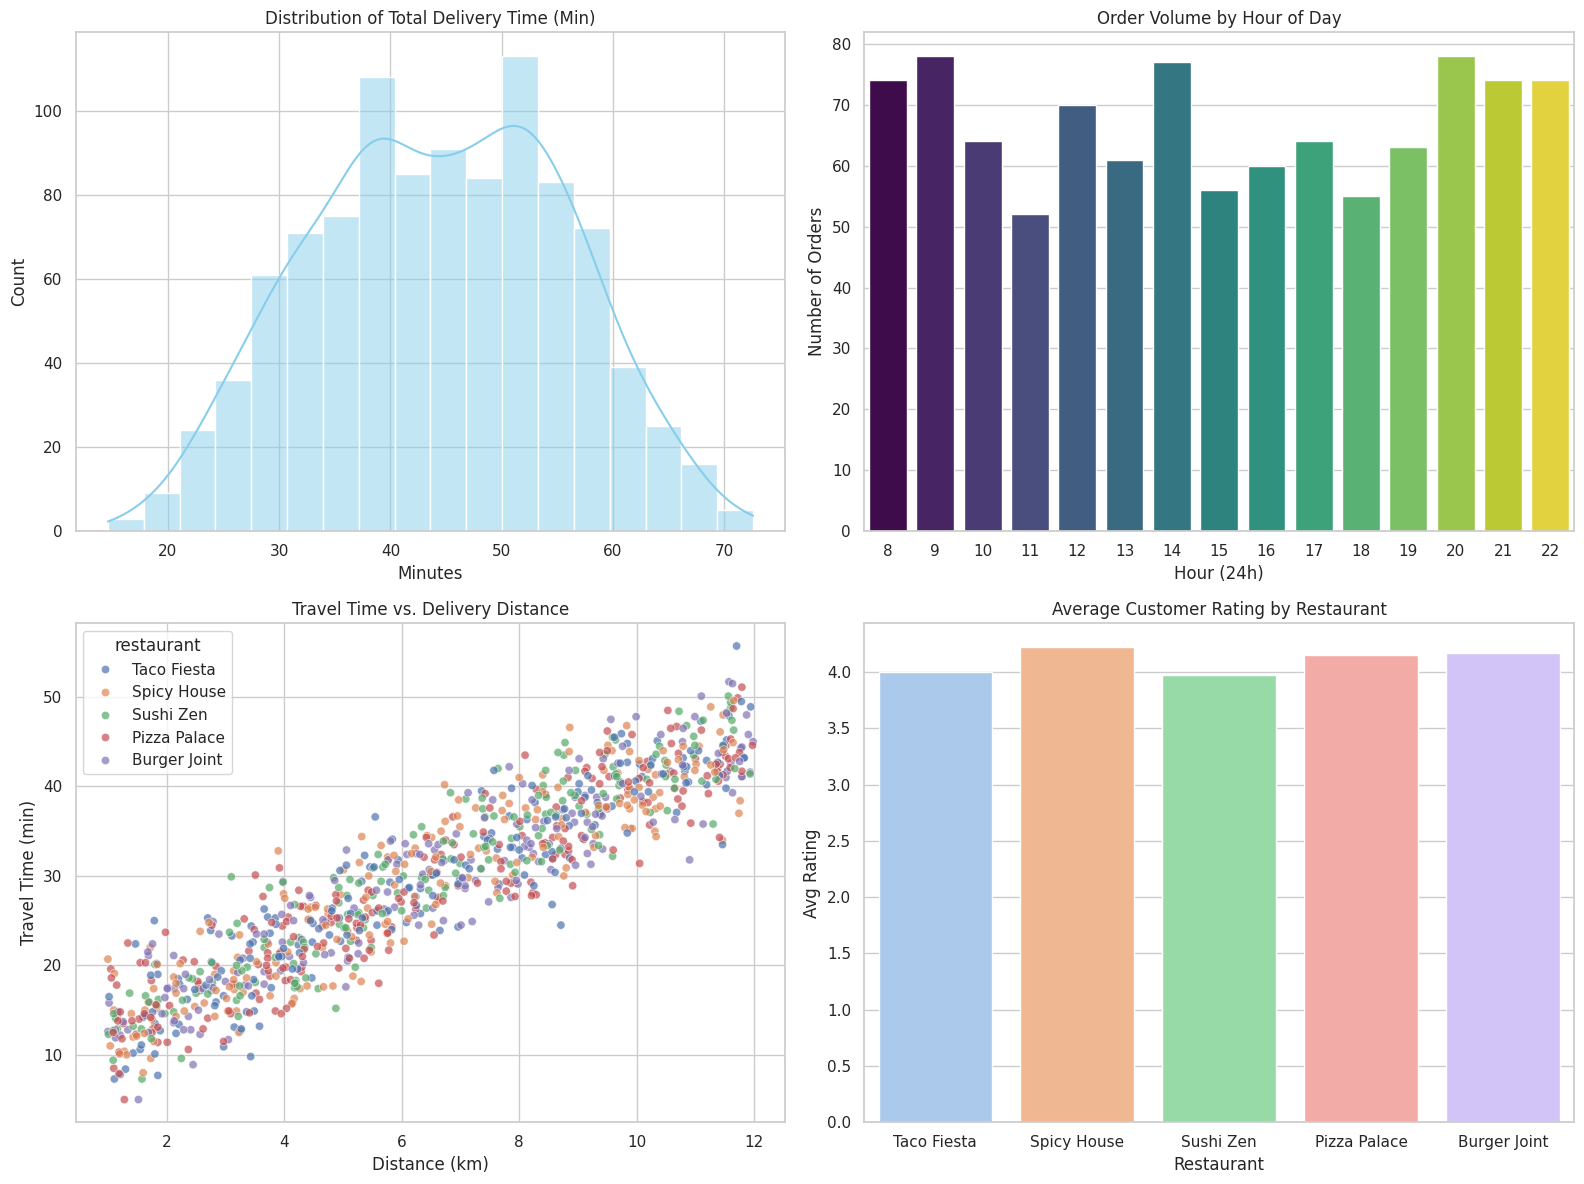


--- Operational Performance Summary ---


,total_orders,avg_prep_time,avg_delivery_time,avg_order_value,avg_rating
restaurant,,,,,
Burger Joint,181,14.79,44.51,25.47,4.17
Pizza Palace,227,15.58,44.37,24.71,4.15
Spicy House,202,14.60,43.56,24.99,4.22
Sushi Zen,187,14.85,45.19,24.78,3.98
Taco Fiesta,203,15.08,44.16,23.85,4.00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Set random seed for reproducibility
np.random.seed(42)

# 1. Simulate Food Delivery & Operations Dataset
n_orders = 1000

# Generate Order IDs and Dates over the last 30 days
start_date = datetime(2023, 10, 1)
date_list = [start_date + timedelta(days=np.random.randint(0, 30),
                                    hours=np.random.randint(8, 23),
                                    minutes=np.random.randint(0, 60))
             for _ in range(n_orders)]

# Generate operational metrics
restaurants = ['Spicy House', 'Burger Joint', 'Sushi Zen', 'Pizza Palace', 'Taco Fiesta']
cuisines = ['Indian', 'American', 'Japanese', 'Italian', 'Mexican']
restaurant_cuisine_map = dict(zip(restaurants, cuisines))

order_restaurants = np.random.choice(restaurants, size=n_orders)
order_cuisines = [restaurant_cuisine_map[r] for r in order_restaurants]

# Distance from restaurant to customer in km
delivery_distance = np.random.uniform(1.0, 12.0, size=n_orders)

# Preparation time (minutes)
prep_time = np.random.normal(loc=15, scale=5, size=n_orders).clip(5, 45)

# Travel time (influenced by distance + random noise)
travel_time = (delivery_distance * 3 + np.random.normal(loc=10, scale=4, size=n_orders)).clip(5, 60)

# Total delivery time
total_delivery_time = prep_time + travel_time

# Order value and ratings
order_value = np.random.normal(loc=25, scale=10, size=n_orders).clip(8, 120)
rating = np.random.choice([1, 2, 3, 4, 5], size=n_orders, p=[0.05, 0.05, 0.1, 0.3, 0.5])

# Create DataFrame
df = pd.DataFrame({
    'order_id': [f'ORD_{i:04d}' for i in range(1, n_orders + 1)],
    'order_time': date_list,
    'restaurant': order_restaurants,
    'cuisine': order_cuisines,
    'distance_km': np.round(delivery_distance, 2),
    'prep_time_min': np.round(prep_time, 1),
    'travel_time_min': np.round(travel_time, 1),
    'total_time_min': np.round(total_delivery_time, 1),
    'order_value_usd': np.round(order_value, 2),
    'rating': rating
})

# Extract temporal features
df['day_of_week'] = df['order_time'].dt.day_name()
df['hour_of_day'] = df['order_time'].dt.hour

print("--- Dataset Overview ---")
print(df.info())
print("\n--- First 5 Rows of Operational Data ---")
display(df.head())

# 2. Exploratory Data Analysis & Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# A. Distribution of Total Delivery Time
sns.histplot(df['total_time_min'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Total Delivery Time (Min)')
axes[0, 0].set_xlabel('Minutes')

# B. Order Volume by Hour of the Day
sns.countplot(data=df, x='hour_of_day', hue='hour_of_day', ax=axes[0, 1], palette='viridis', legend=False)
axes[0, 1].set_title('Order Volume by Hour of Day')
axes[0, 1].set_xlabel('Hour (24h)')
axes[0, 1].set_ylabel('Number of Orders')

# C. Relationship between Distance and Travel Time
sns.scatterplot(data=df, x='distance_km', y='travel_time_min', hue='restaurant', ax=axes[1, 0], alpha=0.7)
axes[1, 0].set_title('Travel Time vs. Delivery Distance')
axes[1, 0].set_xlabel('Distance (km)')
axes[1, 0].set_ylabel('Travel Time (min)')

# D. Average Rating by Restaurant
sns.barplot(data=df, x='restaurant', y='rating', hue='restaurant', ax=axes[1, 1], palette='pastel', errorbar=None, legend=False)
axes[1, 1].set_title('Average Customer Rating by Restaurant')
axes[1, 1].set_xlabel('Restaurant')
axes[1, 1].set_ylabel('Avg Rating')

plt.tight_layout()
plt.show()

# 3. Operational Insights & Metrics Summary
print("\n--- Operational Performance Summary ---")
metrics_summary = df.groupby('restaurant').agg(
    total_orders=('order_id', 'count'),
    avg_prep_time=('prep_time_min', 'mean'),
    avg_delivery_time=('total_time_min', 'mean'),
    avg_order_value=('order_value_usd', 'mean'),
    avg_rating=('rating', 'mean')
).round(2)

display(metrics_summary)

In [3]:
# Grouping operational metrics by cuisine to compare performance
cuisine_summary = df.groupby('cuisine').agg(
    total_orders=('order_id', 'count'),
    avg_prep_time_min=('prep_time_min', 'mean'),
    avg_delivery_time_min=('total_time_min', 'mean'),
    avg_order_value_usd=('order_value_usd', 'mean'),
    avg_rating=('rating', 'mean')
).round(2).sort_values(by='total_orders', ascending=False)

print("--- Cuisine Performance Comparison Summary ---")
display(cuisine_summary)

--- Cuisine Performance Comparison Summary ---


,total_orders,avg_prep_time_min,avg_delivery_time_min,avg_order_value_usd,avg_rating
cuisine,,,,,
Italian,227,15.58,44.37,24.71,4.15
Mexican,203,15.08,44.16,23.85,4.00
Indian,202,14.60,43.56,24.99,4.22
Japanese,187,14.85,45.19,24.78,3.98
American,181,14.79,44.51,25.47,4.17


--- Correlation Analysis ---
Pearson correlation coefficient: -0.0271 (p-value: 3.9238e-01)
Spearman rank correlation coefficient: -0.0276 (p-value: 3.8327e-01)


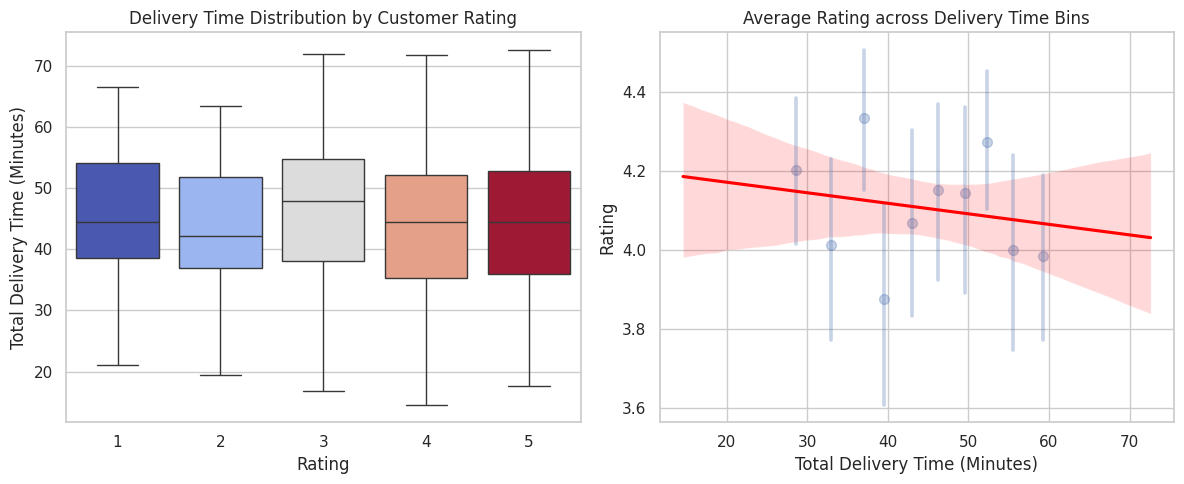

In [4]:
import scipy.stats as stats

# Calculate Pearson and Spearman correlation coefficients
pearson_corr, p_value_p = stats.pearsonr(df['total_time_min'], df['rating'])
spearman_corr, p_value_s = stats.spearmanr(df['total_time_min'], df['rating'])

print("--- Correlation Analysis ---")
print(f"Pearson correlation coefficient: {pearson_corr:.4f} (p-value: {p_value_p:.4e})")
print(f"Spearman rank correlation coefficient: {spearman_corr:.4f} (p-value: {p_value_s:.4e})")

# Visualize the relationship
plt.figure(figsize=(12, 5))

# Subplot 1: Boxplot showing delivery times across ratings
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='rating', y='total_time_min', hue='rating', palette='coolwarm', legend=False)
plt.title('Delivery Time Distribution by Customer Rating')
plt.xlabel('Rating')
plt.ylabel('Total Delivery Time (Minutes)')

# Subplot 2: Local Regression (Lowess) to see general non-linear trend
plt.subplot(1, 2, 2)
sns.regplot(data=df, x='total_time_min', y='rating', scatter_kws={'alpha':0.3}, line_kws={'color':'red'}, x_bins=10)
plt.title('Average Rating across Delivery Time Bins')
plt.xlabel('Total Delivery Time (Minutes)')
plt.ylabel('Rating')

plt.tight_layout()
plt.show()

--- Average Delivery Time per Hour of Day ---


,hour_of_day,total_time_min
0,8,43.16
1,9,41.92
2,10,43.32
3,11,46.18
4,12,43.77
5,13,43.99
6,14,46.37
7,15,44.18
8,16,46.28
9,17,46.01


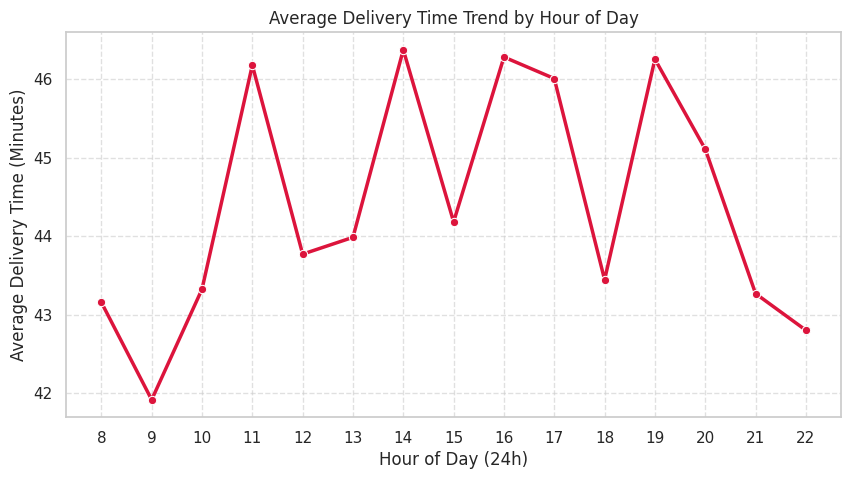

In [5]:
# Calculate average delivery time per hour of day
hourly_delivery_performance = df.groupby('hour_of_day')['total_time_min'].mean().reset_index()

print("--- Average Delivery Time per Hour of Day ---")
display(hourly_delivery_performance.round(2))

# Visualize the hourly delivery time trend
plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_delivery_performance, x='hour_of_day', y='total_time_min', marker='o', color='crimson', linewidth=2.5)
plt.title('Average Delivery Time Trend by Hour of Day')
plt.xlabel('Hour of Day (24h)')
plt.ylabel('Average Delivery Time (Minutes)')
plt.xticks(range(8, 23))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [6]:
# Filter for deliveries exceeding 50 minutes
delayed_orders = df[df['total_time_min'] > 50]

print(f"--- Delayed Deliveries (> 50 mins): {len(delayed_orders)} orders out of {len(df)} ({len(delayed_orders)/len(df)*100:.1f}%) ---")
display(delayed_orders.head())

# Analyze breakdown of delayed orders by restaurant and cuisine
delayed_breakdown = delayed_orders.groupby(['restaurant', 'cuisine']).agg(
    delayed_count=('order_id', 'count'),
    avg_delayed_time=('total_time_min', 'mean'),
    avg_delayed_rating=('rating', 'mean')
).reset_index().sort_values(by='delayed_count', ascending=False)

print("\n--- Breakdown of Delayed Orders by Restaurant ---")
display(delayed_breakdown)

--- Delayed Deliveries (> 50 mins): 353 orders out of 1000 (35.3%) ---


,order_id,order_time,restaurant,cuisine,distance_km,prep_time_min,travel_time_min,total_time_min,order_value_usd,rating,day_of_week,hour_of_day
3,ORD_0004,2023-10-26 10:22:00,Sushi Zen,Japanese,8.76,15.3,43.5,58.8,29.01,2,Thursday,10
5,ORD_0006,2023-10-21 11:39:00,Sushi Zen,Japanese,5.12,20.8,29.6,50.4,8.00,5,Saturday,11
9,ORD_0010,2023-10-02 19:20:00,Taco Fiesta,Mexican,10.79,18.2,43.2,61.4,27.03,4,Monday,19
13,ORD_0014,2023-10-27 22:41:00,Pizza Palace,Italian,8.10,10.9,43.5,54.4,32.32,4,Friday,22
14,ORD_0015,2023-10-28 19:15:00,Sushi Zen,Japanese,8.01,16.8,35.5,52.4,35.33,5,Saturday,19



--- Breakdown of Delayed Orders by Restaurant ---


,restaurant,cuisine,delayed_count,avg_delayed_time,avg_delayed_rating
1,Pizza Palace,Italian,78,56.753846,4.230769
3,Sushi Zen,Japanese,77,56.294805,3.987013
4,Taco Fiesta,Mexican,70,56.944286,3.928571
2,Spicy House,Indian,68,56.613235,4.235294
0,Burger Joint,American,60,56.390000,4.100000


--- Impact of Delays (>50 mins) on Ratings by Cuisine ---


,Avg Rating (On-Time),Avg Rating (Delayed),Rating Drop
cuisine,,,
Mexican,4.038,3.929,-0.109
American,4.207,4.100,-0.107
Japanese,3.973,3.987,0.014
Indian,4.216,4.235,0.019
Italian,4.107,4.231,0.123


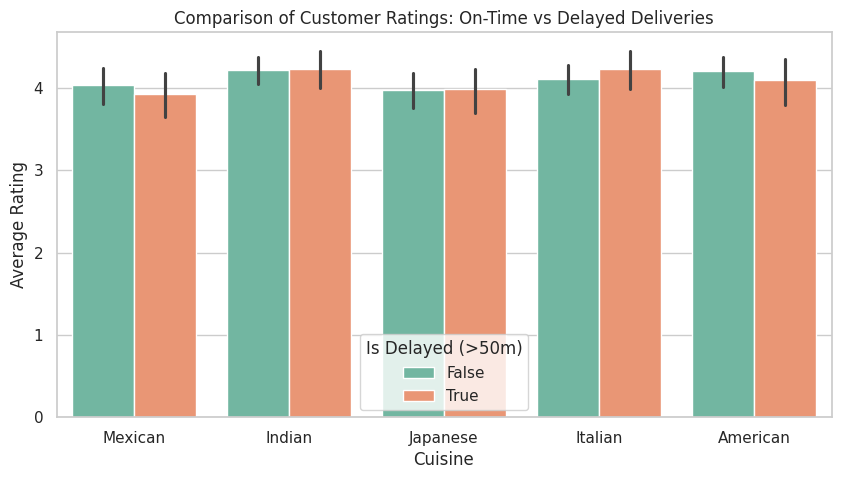

In [7]:
# Identify the impact of delays on customer ratings by cuisine
# Tag each order as delayed (>50 min) or on-time (<=50 min)
df['is_delayed'] = df['total_time_min'] > 50

# Calculate average ratings for on-time vs delayed orders per cuisine
cuisine_delay_impact = df.groupby(['cuisine', 'is_delayed'])['rating'].mean().unstack()
cuisine_delay_impact.columns = ['Avg Rating (On-Time)', 'Avg Rating (Delayed)']

# Calculate the rating drop (delay impact)
cuisine_delay_impact['Rating Drop'] = cuisine_delay_impact['Avg Rating (Delayed)'] - cuisine_delay_impact['Avg Rating (On-Time)']
cuisine_delay_impact = cuisine_delay_impact.sort_values(by='Rating Drop')

print("--- Impact of Delays (>50 mins) on Ratings by Cuisine ---")
display(cuisine_delay_impact.round(3))

# Visualize the rating comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='cuisine', y='rating', hue='is_delayed', palette='Set2')
plt.title('Comparison of Customer Ratings: On-Time vs Delayed Deliveries')
plt.xlabel('Cuisine')
plt.ylabel('Average Rating')
plt.legend(title='Is Delayed (>50m)')
plt.show()

--- Average Order Value Comparison ---


,is_delayed,avg_order_value,median_order_value,total_orders
0,False,24.53,24.61,647
1,True,25.14,24.95,353



Two-sample t-test results:
t-statistic: -1.0001
p-value: 0.3176


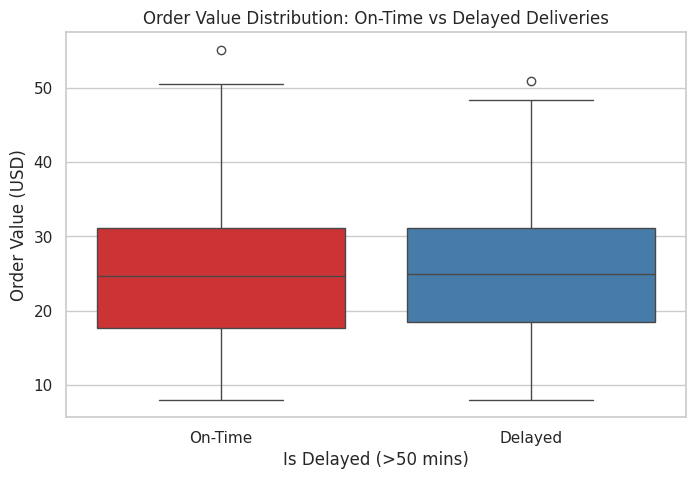

In [8]:
import scipy.stats as stats

# Group by delay status and calculate average order value
order_value_comparison = df.groupby('is_delayed')['order_value_usd'].agg(
    avg_order_value=('mean'),
    median_order_value=('median'),
    total_orders=('count')
).reset_index()

print("--- Average Order Value Comparison ---")
display(order_value_comparison.round(2))

# Perform a t-test to check statistical significance
on_time_values = df[~df['is_delayed']]['order_value_usd']
delayed_values = df[df['is_delayed']]['order_value_usd']

t_stat, p_val = stats.ttest_ind(on_time_values, delayed_values, equal_var=False)
print(f"\nTwo-sample t-test results:\nt-statistic: {t_stat:.4f}\np-value: {p_val:.4f}")

# Visualize the distribution comparison
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='is_delayed', y='order_value_usd', palette='Set1', hue='is_delayed', legend=False)
plt.title('Order Value Distribution: On-Time vs Delayed Deliveries')
plt.xlabel('Is Delayed (>50 mins)')
plt.ylabel('Order Value (USD)')
plt.xticks([0, 1], ['On-Time', 'Delayed'])
plt.show()

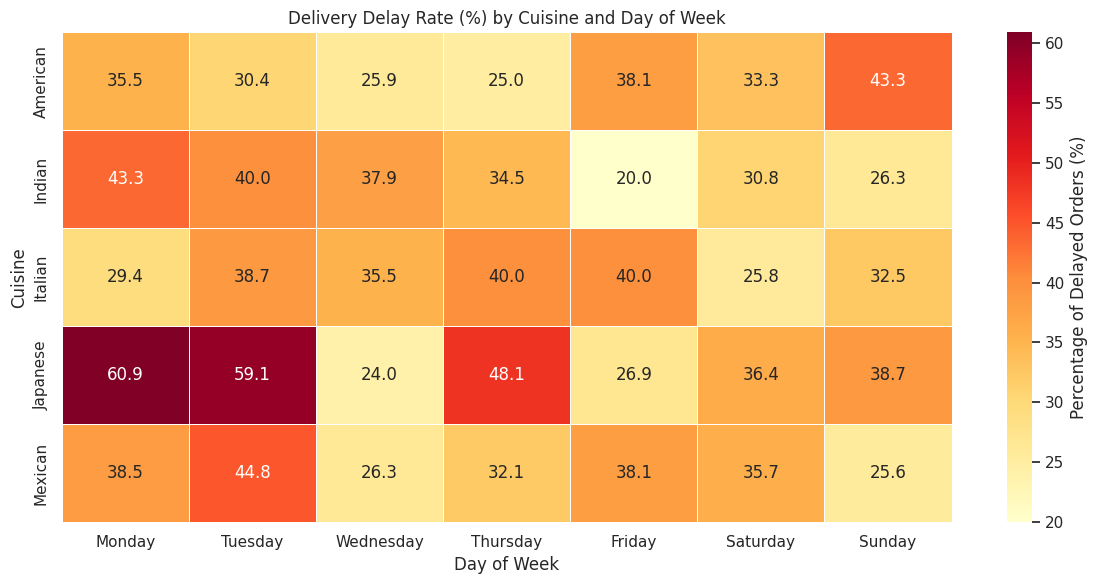

In [9]:
# Calculate delay rate (percentage of orders delayed) by cuisine and day of the week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

delay_heatmap_data = df.groupby(['cuisine', 'day_of_week'])['is_delayed'].mean().unstack()[day_order] * 100

plt.figure(figsize=(12, 6))
sns.heatmap(
    delay_heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={'label': 'Percentage of Delayed Orders (%)'},
    linewidths=0.5
)

plt.title('Delivery Delay Rate (%) by Cuisine and Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Cuisine')
plt.tight_layout()
plt.show()

--- Order Volume Comparison (Weekdays vs. Weekends) ---


,day_type,total_orders,unique_days_count,normalized_daily_avg
0,Weekday,683,5,136.6
1,Weekend,317,2,158.5


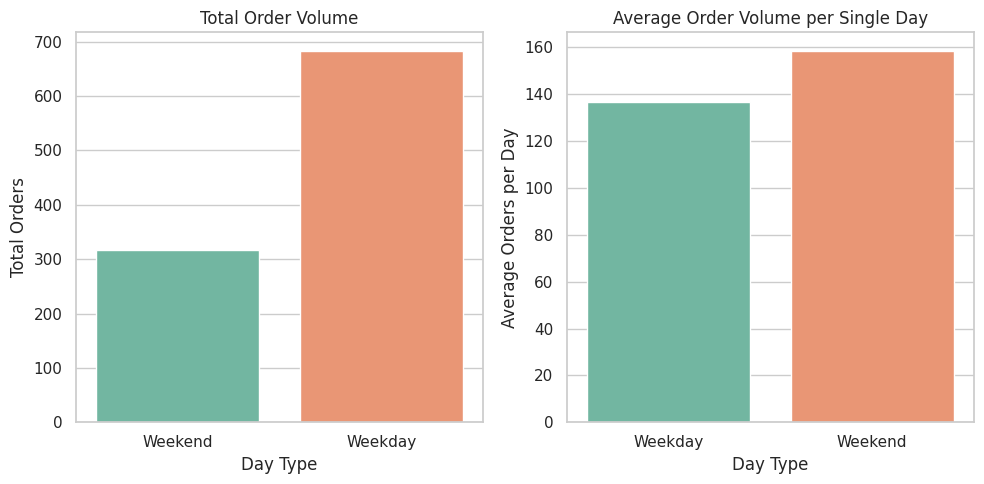

In [10]:
# Categorize each order as Weekday (Mon-Fri) or Weekend (Sat-Sun)
df['is_weekend_day'] = df['day_of_week'].isin(['Saturday', 'Sunday'])
df['day_type'] = df['is_weekend_day'].map({True: 'Weekend', False: 'Weekday'})

# Calculate total order volumes and daily averages
volume_comparison = df.groupby('day_type').agg(
    total_orders=('order_id', 'count'),
    unique_days_count=('day_of_week', lambda x: x.nunique())
).reset_index()

# Since a week has 5 weekdays and 2 weekend days, let's normalize to find average volume per day of that type
volume_comparison['normalized_daily_avg'] = np.where(
    volume_comparison['day_type'] == 'Weekday',
    volume_comparison['total_orders'] / 5,
    volume_comparison['total_orders'] / 2
)

print("--- Order Volume Comparison (Weekdays vs. Weekends) ---")
display(volume_comparison.round(2))

# Plot the comparison
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='day_type', hue='day_type', palette='Set2', legend=False)
plt.title('Total Order Volume')
plt.xlabel('Day Type')
plt.ylabel('Total Orders')

plt.subplot(1, 2, 2)
sns.barplot(data=volume_comparison, x='day_type', y='normalized_daily_avg', hue='day_type', palette='Set2', legend=False)
plt.title('Average Order Volume per Single Day')
plt.xlabel('Day Type')
plt.ylabel('Average Orders per Day')

plt.tight_layout()
plt.show()

--- Daily Metrics Table (Sample) ---


,order_date,daily_order_volume,daily_avg_prep_time
0,2023-10-01,42,14.08
1,2023-10-02,28,14.71
2,2023-10-03,38,16.39
3,2023-10-04,32,15.36
4,2023-10-05,36,16.42
5,2023-10-06,30,15.41
6,2023-10-07,30,14.85
7,2023-10-08,37,14.09
8,2023-10-09,26,14.78
9,2023-10-10,27,14.65



--- Correlation Results ---
Pearson correlation:  r = -0.0204 (p-value = 9.1479e-01)
Spearman correlation: ρ = 0.1012 (p-value = 5.9483e-01)


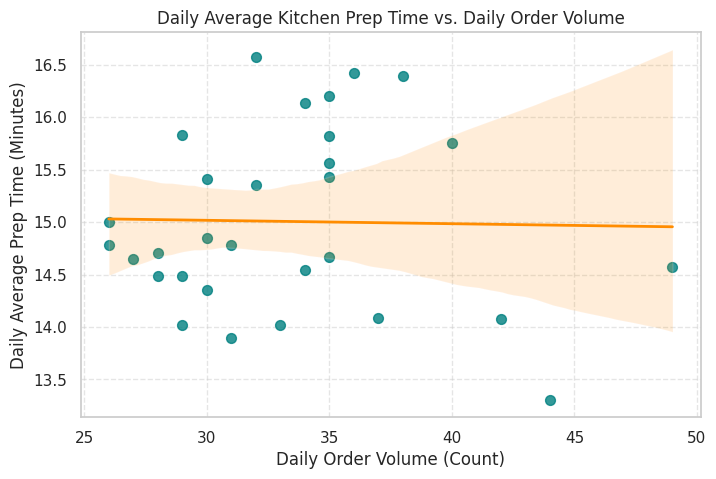

In [11]:
import scipy.stats as stats

# Group the dataset by calendar day to find order volume and average prep time per day
df['order_date'] = df['order_time'].dt.date

daily_metrics = df.groupby('order_date').agg(
    daily_order_volume=('order_id', 'count'),
    daily_avg_prep_time=('prep_time_min', 'mean')
).reset_index()

# Compute Pearson and Spearman correlation coefficients
pearson_r, pearson_p = stats.pearsonr(daily_metrics['daily_order_volume'], daily_metrics['daily_avg_prep_time'])
spearman_r, spearman_p = stats.spearmanr(daily_metrics['daily_order_volume'], daily_metrics['daily_avg_prep_time'])

print("--- Daily Metrics Table (Sample) ---")
display(daily_metrics.head(10).round(2))

print("\n--- Correlation Results ---")
print(f"Pearson correlation:  r = {pearson_r:.4f} (p-value = {pearson_p:.4e})")
print(f"Spearman correlation: ρ = {spearman_r:.4f} (p-value = {spearman_p:.4e})")

# Plot the relationship
plt.figure(figsize=(8, 5))
sns.regplot(
    data=daily_metrics,
    x='daily_order_volume',
    y='daily_avg_prep_time',
    color='teal',
    scatter_kws={'s': 50, 'alpha': 0.8},
    line_kws={'color': 'darkorange', 'lw': 2}
)
plt.title('Daily Average Kitchen Prep Time vs. Daily Order Volume')
plt.xlabel('Daily Order Volume (Count)')
plt.ylabel('Daily Average Prep Time (Minutes)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- Correlation: Distance vs. Total Delivery Time ---
Pearson correlation:  r = 0.8410 (p-value = 1.9315e-268)
Spearman correlation: ρ = 0.8474 (p-value = 1.3910e-276)


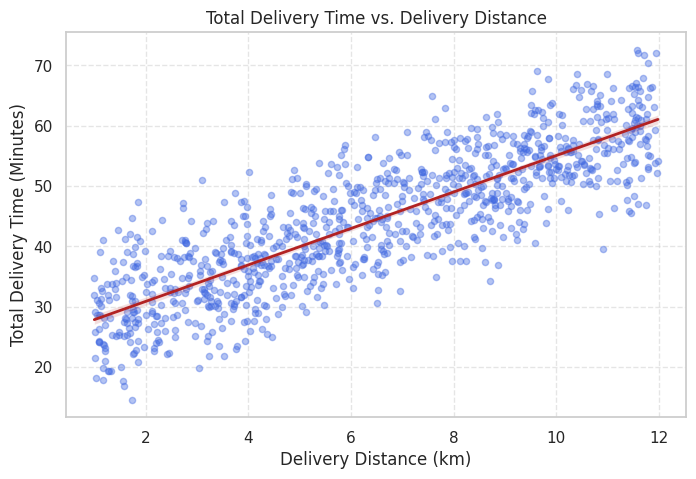

In [12]:
import scipy.stats as stats

# Calculate Pearson and Spearman correlation between distance and total delivery time
pearson_r, pearson_p = stats.pearsonr(df['distance_km'], df['total_time_min'])
spearman_r, spearman_p = stats.spearmanr(df['distance_km'], df['total_time_min'])

print("--- Correlation: Distance vs. Total Delivery Time ---")
print(f"Pearson correlation:  r = {pearson_r:.4f} (p-value = {pearson_p:.4e})")
print(f"Spearman correlation: ρ = {spearman_r:.4f} (p-value = {spearman_p:.4e})")

# Visualize the relationship with a scatter plot and trend line
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x='distance_km',
    y='total_time_min',
    color='royalblue',
    scatter_kws={'alpha': 0.4, 's': 20},
    line_kws={'color': 'firebrick', 'lw': 2}
)
plt.title('Total Delivery Time vs. Delivery Distance')
plt.xlabel('Delivery Distance (km)')
plt.ylabel('Total Delivery Time (Minutes)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

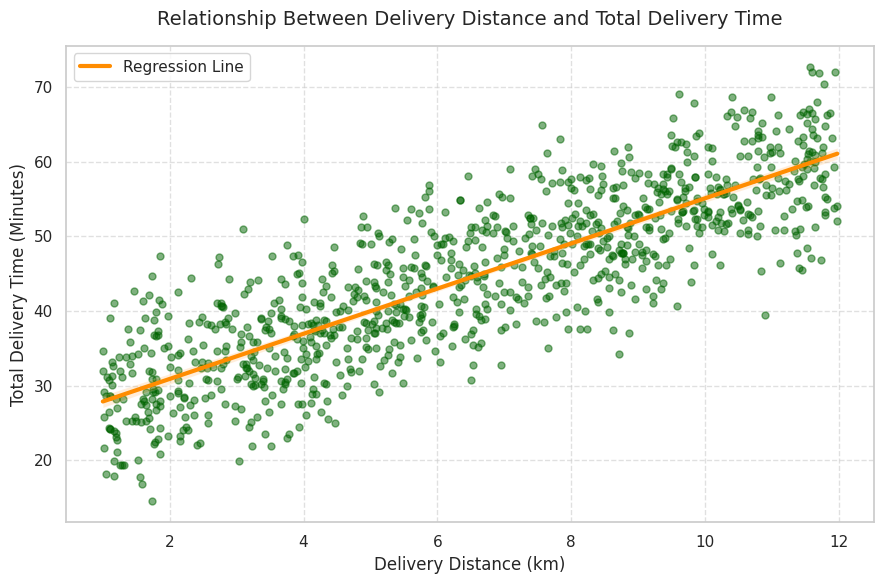

In [13]:
# Create a dedicated regression plot visualizing delivery distance vs total delivery time
plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x='distance_km',
    y='total_time_min',
    color='forestgreen',
    scatter_kws={'alpha': 0.5, 's': 25, 'color': 'darkgreen'},
    line_kws={'color': 'darkorange', 'lw': 3, 'label': 'Regression Line'}
)

plt.title('Relationship Between Delivery Distance and Total Delivery Time', fontsize=14, pad=15)
plt.xlabel('Delivery Distance (km)', fontsize=12)
plt.ylabel('Total Delivery Time (Minutes)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

--- Restaurant Efficiency: Delivery Time per Kilometer ---


,restaurant,avg_time_per_km,median_time_per_km,total_orders
3,Sushi Zen,8.50,6.87,187
0,Burger Joint,8.56,6.58,181
4,Taco Fiesta,8.71,7.00,203
2,Spicy House,8.72,6.82,202
1,Pizza Palace,9.05,7.02,227


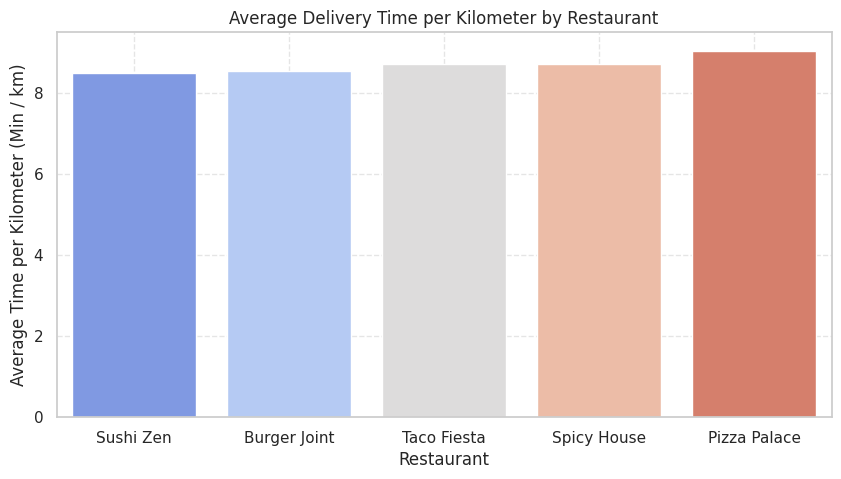

In [14]:
# Calculate delivery time per kilometer for each individual order
df['time_per_km'] = df['total_time_min'] / df['distance_km']

# Group by restaurant to find the average time per kilometer
restaurant_efficiency = df.groupby('restaurant').agg(
    avg_time_per_km=('time_per_km', 'mean'),
    median_time_per_km=('time_per_km', 'median'),
    total_orders=('order_id', 'count')
).reset_index().sort_values(by='avg_time_per_km')

print("--- Restaurant Efficiency: Delivery Time per Kilometer ---")
display(restaurant_efficiency.round(2))

# Visualize the comparison
plt.figure(figsize=(10, 5))
sns.barplot(
    data=restaurant_efficiency,
    x='restaurant',
    y='avg_time_per_km',
    hue='restaurant',
    palette='coolwarm',
    legend=False
)
plt.title('Average Delivery Time per Kilometer by Restaurant')
plt.xlabel('Restaurant')
plt.ylabel('Average Time per Kilometer (Min / km)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- Correlation: Delivery Time per KM vs. Customer Rating ---
Pearson correlation:  r = 0.0048 (p-value = 8.8000e-01)
Spearman correlation: ρ = 0.0159 (p-value = 6.1610e-01)


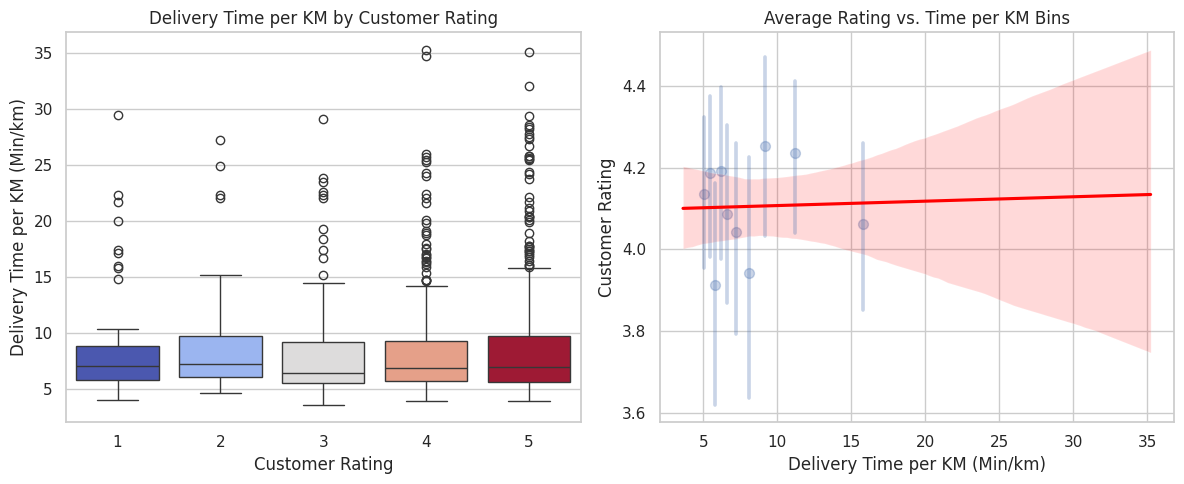

In [15]:
import scipy.stats as stats

# Calculate Pearson and Spearman correlation between time_per_km and rating
pearson_r, pearson_p = stats.pearsonr(df['time_per_km'], df['rating'])
spearman_r, spearman_p = stats.spearmanr(df['time_per_km'], df['rating'])

print("--- Correlation: Delivery Time per KM vs. Customer Rating ---")
print(f"Pearson correlation:  r = {pearson_r:.4f} (p-value = {pearson_p:.4e})")
print(f"Spearman correlation: ρ = {spearman_r:.4f} (p-value = {spearman_p:.4e})")

# Visualize the distribution of time_per_km across different rating scores
plt.figure(figsize=(12, 5))

# Subplot 1: Boxplot of Time per KM by Rating
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='rating', y='time_per_km', hue='rating', palette='coolwarm', legend=False)
plt.title('Delivery Time per KM by Customer Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Delivery Time per KM (Min/km)')

# Subplot 2: Regression Trend across Rating
plt.subplot(1, 2, 2)
sns.regplot(data=df, x='time_per_km', y='rating', scatter_kws={'alpha':0.3}, line_kws={'color':'red'}, x_bins=10)
plt.title('Average Rating vs. Time per KM Bins')
plt.xlabel('Delivery Time per KM (Min/km)')
plt.ylabel('Customer Rating')

plt.tight_layout()
plt.show()

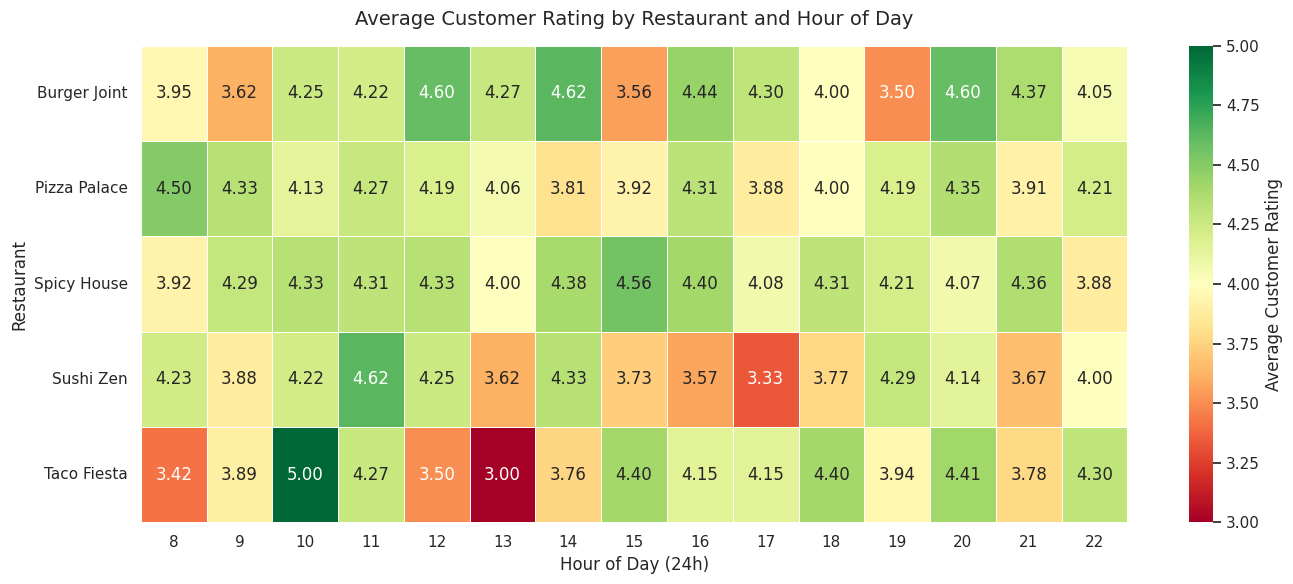

In [16]:
# Create a pivot table of average ratings by restaurant and hour of the day
rating_heatmap_data = df.groupby(['restaurant', 'hour_of_day'])['rating'].mean().unstack()

# Visualize the ratings as a heatmap
plt.figure(figsize=(14, 6))
sns.heatmap(
    rating_heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=4.0,
    cbar_kws={'label': 'Average Customer Rating'},
    linewidths=0.5
)

plt.title('Average Customer Rating by Restaurant and Hour of Day', fontsize=14, pad=15)
plt.xlabel('Hour of Day (24h)', fontsize=12)
plt.ylabel('Restaurant', fontsize=12)
plt.tight_layout()
plt.show()

--- Restaurant Performance Consistency Across Hours ---
Sorted by Standard Deviation (lower value = more consistent performance across hours)


,restaurant,overall_mean_rating,rating_std_dev,min_rating,max_rating
2,Spicy House,4.228,0.195,3.875,4.556
1,Pizza Palace,4.137,0.203,3.812,4.500
3,Sushi Zen,3.977,0.358,3.333,4.625
0,Burger Joint,4.157,0.373,3.500,4.625
4,Taco Fiesta,4.026,0.493,3.000,5.000


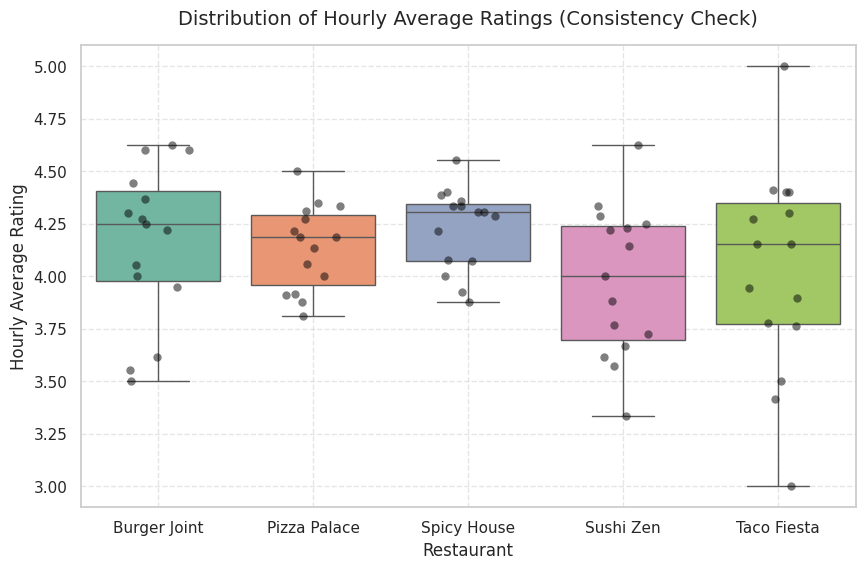

In [17]:
# Calculate consistency metrics (mean and standard deviation) of ratings across hours for each restaurant
hourly_restaurant_stats = df.groupby(['restaurant', 'hour_of_day'])['rating'].mean().groupby('restaurant').agg(
    overall_mean_rating='mean',
    rating_std_dev='std',
    min_rating='min',
    max_rating='max'
).reset_index().sort_values(by='rating_std_dev')

print("--- Restaurant Performance Consistency Across Hours ---")
print("Sorted by Standard Deviation (lower value = more consistent performance across hours)")
display(hourly_restaurant_stats.round(3))

# Visualize consistency using a boxplot of hourly average ratings
hourly_averages = df.groupby(['restaurant', 'hour_of_day'])['rating'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=hourly_averages,
    x='restaurant',
    y='rating',
    hue='restaurant',
    palette='Set2',
    legend=False
)
sns.stripplot(
    data=hourly_averages,
    x='restaurant',
    y='rating',
    color='black',
    alpha=0.5,
    size=6,
    jitter=0.2
)

plt.title('Distribution of Hourly Average Ratings (Consistency Check)', fontsize=14, pad=15)
plt.xlabel('Restaurant', fontsize=12)
plt.ylabel('Hourly Average Rating', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- Prep Time Comparison: Most vs. Least Consistent Restaurants ---


,restaurant,avg_prep_time_min,std_prep_time_min,total_orders
0,Spicy House,14.60,4.99,202
1,Taco Fiesta,15.08,5.16,203



Two-sample t-test results for prep times:
t-statistic: -0.9519
p-value: 0.3417


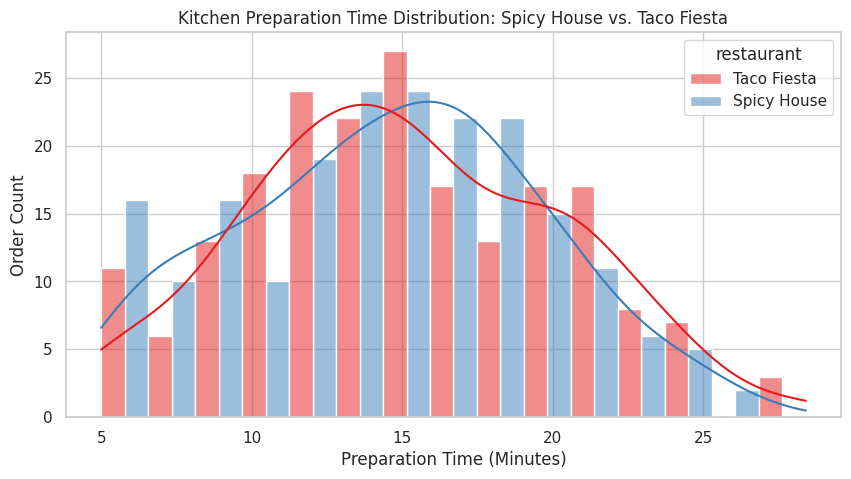

In [18]:
# Filter data for the most and least consistent restaurants
most_consistent = df[df['restaurant'] == 'Spicy House']['prep_time_min']
least_consistent = df[df['restaurant'] == 'Taco Fiesta']['prep_time_min']

# Calculate mean and standard deviation of prep times
prep_comparison = df[df['restaurant'].isin(['Spicy House', 'Taco Fiesta'])].groupby('restaurant').agg(
    avg_prep_time_min=('prep_time_min', 'mean'),
    std_prep_time_min=('prep_time_min', 'std'),
    total_orders=('order_id', 'count')
).reset_index()

print("--- Prep Time Comparison: Most vs. Least Consistent Restaurants ---")
display(prep_comparison.round(2))

# Perform a t-test to check if prep times differ significantly
t_stat, p_val = stats.ttest_ind(most_consistent, least_consistent, equal_var=False)
print(f"\nTwo-sample t-test results for prep times:\nt-statistic: {t_stat:.4f}\np-value: {p_val:.4f}")

# Visualize the distribution of prep times
plt.figure(figsize=(10, 5))
sns.histplot(data=df[df['restaurant'].isin(['Spicy House', 'Taco Fiesta'])], x='prep_time_min', hue='restaurant', kde=True, multiple='dodge', palette='Set1', bins=15)
plt.title('Kitchen Preparation Time Distribution: Spicy House vs. Taco Fiesta')
plt.xlabel('Preparation Time (Minutes)')
plt.ylabel('Order Count')
plt.show()

--- Total Delivery Time Comparison: Spicy House vs. Taco Fiesta ---


,restaurant,avg_delivery_time_min,std_delivery_time_min,total_orders
0,Spicy House,43.56,11.92,202
1,Taco Fiesta,44.16,11.50,203



Two-sample t-test results for delivery times:
t-statistic: -0.5135
p-value: 0.6079


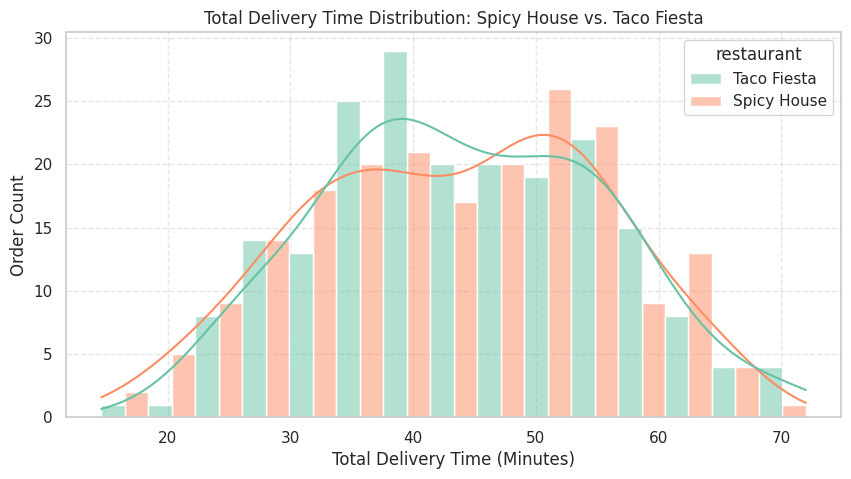

In [19]:
# Filter total delivery times for Spicy House and Taco Fiesta
spicy_house_delivery = df[df['restaurant'] == 'Spicy House']['total_time_min']
taco_fiesta_delivery = df[df['restaurant'] == 'Taco Fiesta']['total_time_min']

# Compute average and standard deviation of total delivery times
delivery_comparison = df[df['restaurant'].isin(['Spicy House', 'Taco Fiesta'])].groupby('restaurant').agg(
    avg_delivery_time_min=('total_time_min', 'mean'),
    std_delivery_time_min=('total_time_min', 'std'),
    total_orders=('order_id', 'count')
).reset_index()

print("--- Total Delivery Time Comparison: Spicy House vs. Taco Fiesta ---")
display(delivery_comparison.round(2))

# Perform a two-sample t-test
t_stat_del, p_val_del = stats.ttest_ind(spicy_house_delivery, taco_fiesta_delivery, equal_var=False)
print(f"\nTwo-sample t-test results for delivery times:\nt-statistic: {t_stat_del:.4f}\np-value: {p_val_del:.4f}")

# Visualize the distribution of total delivery times
plt.figure(figsize=(10, 5))
sns.histplot(data=df[df['restaurant'].isin(['Spicy House', 'Taco Fiesta'])], x='total_time_min', hue='restaurant', kde=True, multiple='dodge', palette='Set2', bins=15)
plt.title('Total Delivery Time Distribution: Spicy House vs. Taco Fiesta')
plt.xlabel('Total Delivery Time (Minutes)')
plt.ylabel('Order Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- Taco Fiesta Off-Peak Hours Delay Analysis (Non-Rush Hours) ---


,is_delayed,avg_rating,order_count
0,False,4.192,52
1,True,3.958,24



Taco Fiesta Rating Drop during Off-Peak Hours due to Delays: -0.234


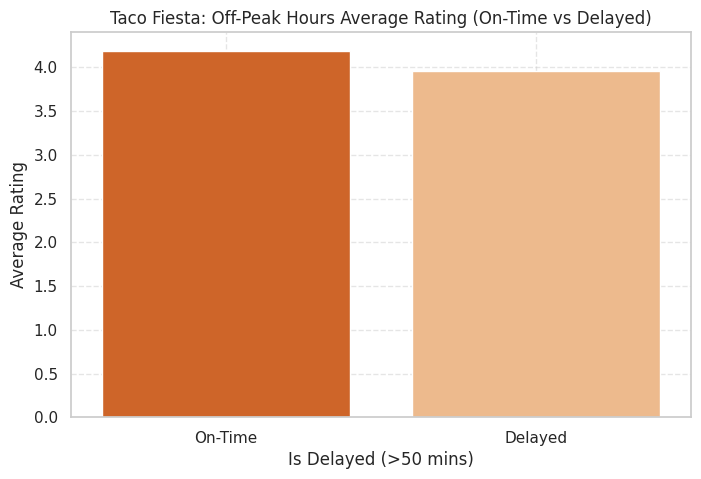

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for Taco Fiesta
taco_df = df[df['restaurant'] == 'Taco Fiesta'].copy()

# Define Peak Hours: Lunch (11-14) and Dinner (17-21)
peak_hours = set(list(range(11, 15)) + list(range(17, 22)))
taco_df['is_peak_hour'] = taco_df['hour_of_day'].isin(peak_hours)

# Filter for off-peak hours only
off_peak_taco = taco_df[~taco_df['is_peak_hour']].copy()

# Calculate average rating for On-Time vs Delayed orders during off-peak
off_peak_stats = off_peak_taco.groupby('is_delayed').agg(
    avg_rating=('rating', 'mean'),
    order_count=('order_id', 'count')
).reset_index()

print("--- Taco Fiesta Off-Peak Hours Delay Analysis (Non-Rush Hours) ---")
display(off_peak_stats.round(3))

# Calculate rating drop
rating_ontime = off_peak_taco[~off_peak_taco['is_delayed']]['rating'].mean()
rating_delayed = off_peak_taco[off_peak_taco['is_delayed']]['rating'].mean()
rating_drop = rating_delayed - rating_ontime

print(f"\nTaco Fiesta Rating Drop during Off-Peak Hours due to Delays: {rating_drop:.3f}")

# Plotting
plt.figure(figsize=(8, 5))
sns.barplot(
    data=off_peak_taco,
    x='is_delayed',
    y='rating',
    hue='is_delayed',
    palette='Oranges_r',
    errorbar=None,
    legend=False
)
plt.title('Taco Fiesta: Off-Peak Hours Average Rating (On-Time vs Delayed)')
plt.xlabel('Is Delayed (>50 mins)')
plt.ylabel('Average Rating')
plt.xticks([0, 1], ['On-Time', 'Delayed'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

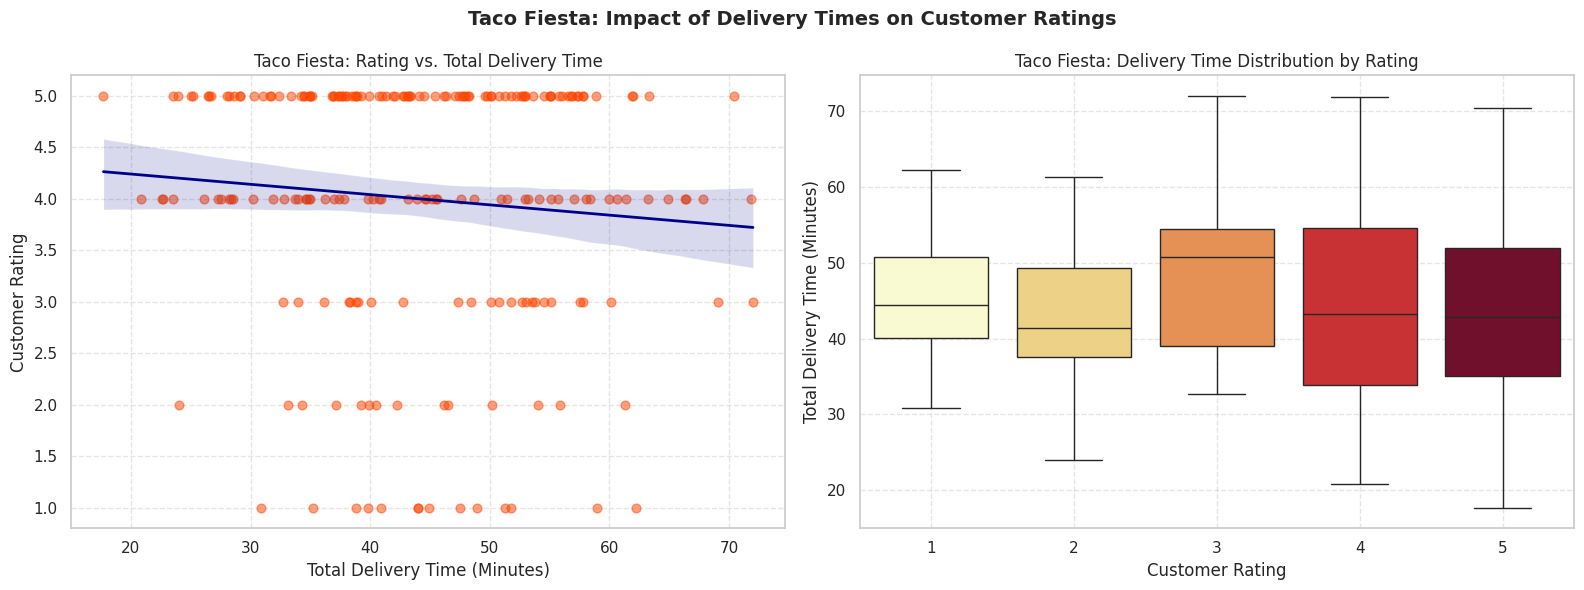

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter dataset for Taco Fiesta
taco_fiesta_df = df[df['restaurant'] == 'Taco Fiesta'].copy()

# Create a multi-plot visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Scatter plot with trendline (regression)
sns.regplot(
    data=taco_fiesta_df,
    x='total_time_min',
    y='rating',
    ax=axes[0],
    color='orangered',
    scatter_kws={'alpha': 0.5, 's': 40},
    line_kws={'color': 'darkblue', 'lw': 2, 'label': 'Trend'}
)
axes[0].set_title('Taco Fiesta: Rating vs. Total Delivery Time')
axes[0].set_xlabel('Total Delivery Time (Minutes)')
axes[0].set_ylabel('Customer Rating')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Boxplot of delivery times for each rating score
sns.boxplot(
    data=taco_fiesta_df,
    x='rating',
    y='total_time_min',
    ax=axes[1],
    hue='rating',
    palette='YlOrRd',
    legend=False
)
axes[1].set_title('Taco Fiesta: Delivery Time Distribution by Rating')
axes[1].set_xlabel('Customer Rating')
axes[1].set_ylabel('Total Delivery Time (Minutes)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Taco Fiesta: Impact of Delivery Times on Customer Ratings', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()